In [2]:
import os

print(os.listdir("/content"))

['.config', 'sample_data']


In [ ]:
from google.colab import files
uploaded = files.upload()

In [3]:
import glob
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

files_found = glob.glob("/content/*.csv")

print("CSV files found:", files_found)

if files_found:
    df = pd.read_csv(files_found[0])
    print("Dataset loaded successfully!")
    print(df.head())
else:
    print("No CSV file found. Please upload the file again.")

CSV files found: []
No CSV file found. Please upload the file again.


In [4]:
from google.colab import files
uploaded = files.upload()

Saving cleaned_sales_data.csv to cleaned_sales_data.csv


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("cleaned_sales_data.csv")

print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
   OrderID   Product  Quantity    Price       City
0      101    Laptop       2.0  50000.0  Hyderabad
1      102     Mouse       5.0    500.0     Mumbai
2      103  Keyboard       3.0   1500.0      Delhi
3      104   Monitor       1.0   8000.0  Hyderabad
4      105    Laptop       2.5  50000.0    Chennai


In [6]:
print("Dataset Information:")
print(df.info())

print("\nNumerical Summary:")
print(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   OrderID   7 non-null      int64  
 1   Product   7 non-null      object 
 2   Quantity  7 non-null      float64
 3   Price     7 non-null      float64
 4   City      7 non-null      object 
dtypes: float64(2), int64(1), object(2)
memory usage: 412.0+ bytes
None

Numerical Summary:
          OrderID  Quantity         Price
count    7.000000  7.000000      7.000000
mean   104.000000  2.785714  16607.142857
std      2.160247  1.349603  22951.877711
min    101.000000  1.000000    500.000000
25%    102.500000  2.000000   1500.000000
50%    104.000000  2.500000   4750.000000
75%    105.500000  3.500000  29000.000000
max    107.000000  5.000000  50000.000000


In [7]:
print("Number of orders for each product:")
print(df["Product"].value_counts())

Number of orders for each product:
Product
Laptop      2
Mouse       2
Keyboard    2
Monitor     1
Name: count, dtype: int64


In [8]:

print("Number of orders for each product:")
print(df["Product"].value_counts())


Number of orders for each product:
Product
Laptop      2
Mouse       2
Keyboard    2
Monitor     1
Name: count, dtype: int64


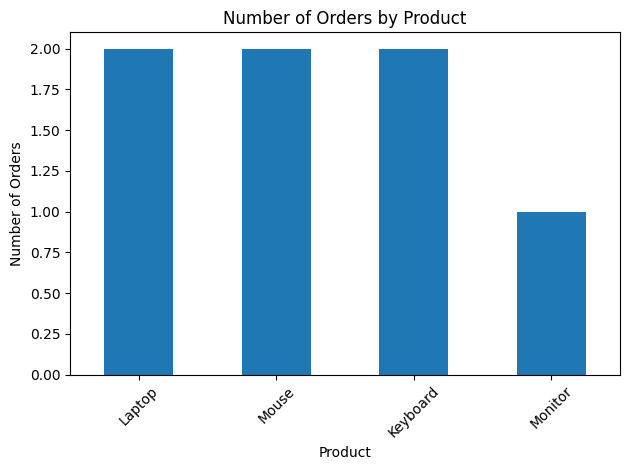

In [9]:

import matplotlib.pyplot as plt

df["Product"].value_counts().plot(kind="bar")

plt.title("Number of Orders by Product")
plt.xlabel("Product")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


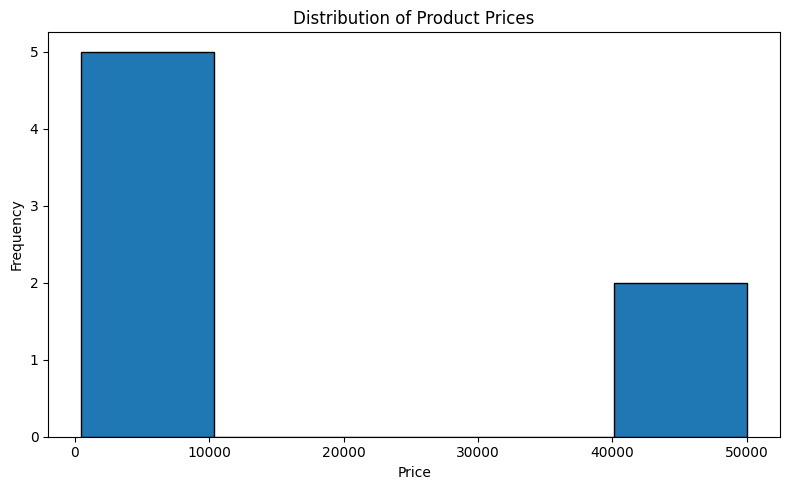

In [10]:

plt.figure(figsize=(8, 5))
plt.hist(df["Price"], bins=5, edgecolor="black")
plt.title("Distribution of Product Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


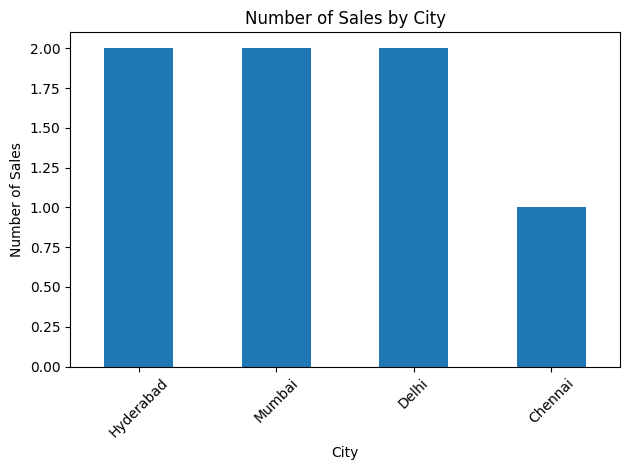

In [11]:

df["City"].value_counts().plot(kind="bar")

plt.title("Number of Sales by City")
plt.xlabel("City")
plt.ylabel("Number of Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


           OrderID  Quantity     Price
OrderID   1.000000 -0.142915 -0.297489
Quantity -0.142915  1.000000 -0.332728
Price    -0.297489 -0.332728  1.000000


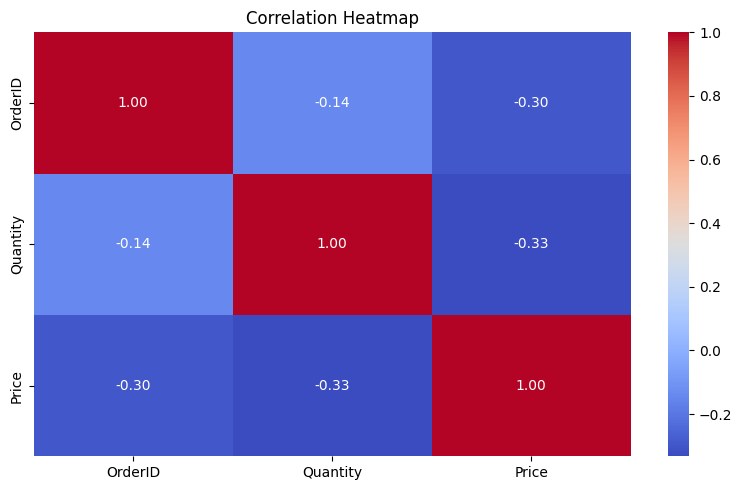

In [12]:

import seaborn as sns
import matplotlib.pyplot as plt

numeric_df = df.select_dtypes(include="number")

correlation = numeric_df.corr()

print(correlation)

plt.figure(figsize=(8, 5))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


In [13]:

import sqlite3
import pandas as pd

connection = sqlite3.connect("sales_analysis.db")

df.to_sql("sales", connection, if_exists="replace", index=False)

print("SQL database created successfully!")
print("Sales table created successfully!")


SQL database created successfully!
Sales table created successfully!


In [14]:

query = """
SELECT Product, COUNT(*) AS NumberOfSales
FROM sales
GROUP BY Product
ORDER BY NumberOfSales DESC;
"""

result = pd.read_sql_query(query, connection)
print(result)


    Product  NumberOfSales
0     Mouse              2
1    Laptop              2
2  Keyboard              2
3   Monitor              1


In [15]:

query = """
SELECT Product, SUM(Quantity) AS TotalQuantity
FROM sales
GROUP BY Product
ORDER BY TotalQuantity DESC;
"""

result = pd.read_sql_query(query, connection)
print(result)


    Product  TotalQuantity
0     Mouse            9.0
1  Keyboard            5.0
2    Laptop            4.5
3   Monitor            1.0


In [16]:

query = """
SELECT Product,
       SUM(Quantity * Price) AS TotalSalesValue
FROM sales
GROUP BY Product
ORDER BY TotalSalesValue DESC;
"""

result = pd.read_sql_query(query, connection)
print(result)


    Product  TotalSalesValue
0    Laptop         225000.0
1     Mouse          21500.0
2   Monitor           8000.0
3  Keyboard           7500.0


In [17]:

query = """
SELECT City, COUNT(*) AS NumberOfSales
FROM sales
WHERE City = 'Hyderabad'
GROUP BY City;
"""

result = pd.read_sql_query(query, connection)
print(result)


        City  NumberOfSales
0  Hyderabad              2


In [18]:

query = """
SELECT Product,
       AVG(Price) AS AveragePrice
FROM sales
GROUP BY Product
ORDER BY AveragePrice DESC;
"""

result = pd.read_sql_query(query, connection)
print(result)


    Product  AveragePrice
0    Laptop       50000.0
1   Monitor        8000.0
2     Mouse        2625.0
3  Keyboard        1500.0


In [19]:

query = """
SELECT Product, MAX(Price) AS HighestPrice
FROM sales
GROUP BY Product
ORDER BY HighestPrice DESC;
"""

result = pd.read_sql_query(query, connection)
print(result)


    Product  HighestPrice
0    Laptop       50000.0
1   Monitor        8000.0
2     Mouse        4750.0
3  Keyboard        1500.0


In [20]:

query = """
SELECT City,
       SUM(Quantity * Price) AS TotalSalesValue
FROM sales
GROUP BY City
ORDER BY TotalSalesValue DESC;
"""

result = pd.read_sql_query(query, connection)
print(result)


        City  TotalSalesValue
0    Chennai         125000.0
1  Hyderabad         108000.0
2     Mumbai          21500.0
3      Delhi           7500.0


In [21]:

total_sales = (df["Quantity"] * df["Price"]).sum()
total_quantity = df["Quantity"].sum()
total_orders = len(df)
total_products = df["Product"].nunique()

print("SALES DASHBOARD SUMMARY")
print("-----------------------")
print("Total Sales Value:", total_sales)
print("Total Quantity Sold:", total_quantity)
print("Total Sales Records:", total_orders)
print("Number of Products:", total_products)


SALES DASHBOARD SUMMARY
-----------------------
Total Sales Value: 262000.0
Total Quantity Sold: 19.5
Total Sales Records: 7
Number of Products: 4


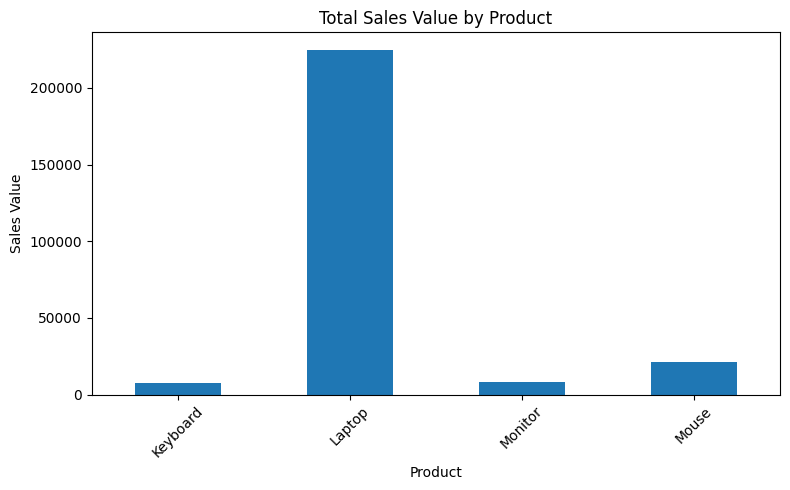

In [22]:

product_sales = df.groupby("Product").apply(
    lambda x: (x["Quantity"] * x["Price"]).sum(),
    include_groups=False
)

product_sales.plot(kind="bar", figsize=(8, 5))

plt.title("Total Sales Value by Product")
plt.xlabel("Product")
plt.ylabel("Sales Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


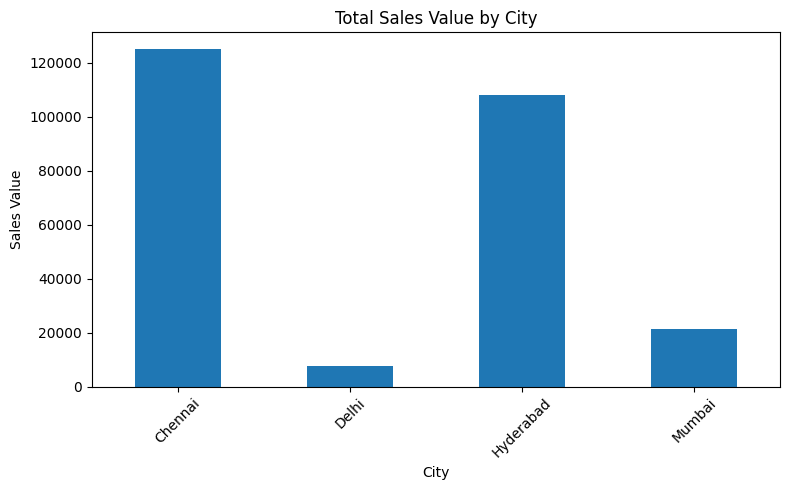

In [23]:

city_sales = df.assign(
    SalesValue=df["Quantity"] * df["Price"]
).groupby("City")["SalesValue"].sum()

city_sales.plot(kind="bar", figsize=(8, 5))

plt.title("Total Sales Value by City")
plt.xlabel("City")
plt.ylabel("Sales Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [30]:

import os

print("Checking dashboard file...")

filename = "/content/ApexPlanet_Task2_Sales_Dashboard.xlsx"

if os.path.exists(filename):
    print("Dashboard file exists!")
    print("File size:", os.path.getsize(filename), "bytes")
else:
    print("Dashboard file not created yet.")


Checking dashboard file...
Dashboard file not created yet.


In [32]:

import pandas as pd
from openpyxl import Workbook
from openpyxl.styles import Font, PatternFill
from openpyxl.chart import BarChart, Reference
from openpyxl.utils import get_column_letter
from google.colab import files
import os

df["SalesValue"] = df["Quantity"] * df["Price"]

product_summary = df.groupby("Product", as_index=False).agg(
    TotalQuantity=("Quantity", "sum"),
    TotalSales=("SalesValue", "sum"),
    AveragePrice=("Price", "mean")
)

city_summary = df.groupby("City", as_index=False).agg(
    TotalSales=("SalesValue", "sum"),
    NumberOfSales=("OrderID", "count")
)

wb = Workbook()
ws = wb.active
ws.title = "Dashboard"

ws["A1"] = "SALES ANALYSIS DASHBOARD"
ws["A1"].font = Font(size=18, bold=True, color="FFFFFF")
ws["A1"].fill = PatternFill("solid", fgColor="176B52")
ws.merge_cells("A1:D1")

summary = [
    ("Total Sales Value", float(df["SalesValue"].sum())),
    ("Total Quantity Sold", float(df["Quantity"].sum())),
    ("Number of Sales Records", int(len(df))),
    ("Number of Products", int(df["Product"].nunique()))
]

for row, (label, value) in enumerate(summary, start=3):
    ws.cell(row=row, column=1, value=label)
    ws.cell(row=row, column=2, value=value)
    ws.cell(row=row, column=1).font = Font(bold=True, color="176B52")
    ws.cell(row=row, column=2).font = Font(bold=True)

product_ws = wb.create_sheet("Product Summary")
product_ws.append(list(product_summary.columns))
for row in product_summary.itertuples(index=False, name=None):
    product_ws.append(list(row))

city_ws = wb.create_sheet("City Summary")
city_ws.append(list(city_summary.columns))
for row in city_summary.itertuples(index=False, name=None):
    city_ws.append(list(row))

data_ws = wb.create_sheet("Sales Data")
data_ws.append(list(df.columns))
for row in df.itertuples(index=False, name=None):
    data_ws.append(list(row))

for sheet in wb.worksheets:
    sheet.freeze_panes = "A2"
    for cell in sheet[1]:
        cell.font = Font(bold=True, color="FFFFFF")
        cell.fill = PatternFill("solid", fgColor="176B52")

    for column_index in range(1, sheet.max_column + 1):
        letter = get_column_letter(column_index)
        lengths = [
            len(str(sheet.cell(r, column_index).value or ""))
            for r in range(1, sheet.max_row + 1)
        ]
        sheet.column_dimensions[letter].width = min(
            max(max(lengths, default=0) + 3, 14), 28
        )

chart1 = BarChart()
chart1.type = "bar"
chart1.title = "Total Sales by Product"
chart1.y_axis.title = "Product"
chart1.x_axis.title = "Sales Value"
chart1.add_data(
    Reference(product_ws, min_col=3, min_row=1, max_row=product_ws.max_row),
    titles_from_data=True
)
chart1.set_categories(
    Reference(product_ws, min_col=1, min_row=2, max_row=product_ws.max_row)
)
ws.add_chart(chart1, "D3")

chart2 = BarChart()
chart2.type = "col"
chart2.title = "Total Sales by City"
chart2.y_axis.title = "Sales Value"
chart2.add_data(
    Reference(city_ws, min_col=2, min_row=1, max_row=city_ws.max_row),
    titles_from_data=True
)
chart2.set_categories(
    Reference(city_ws, min_col=1, min_row=2, max_row=city_ws.max_row)
)
ws.add_chart(chart2, "D20")

filename = "/content/ApexPlanet_Task2_Sales_Dashboard.xlsx"
wb.save(filename)

print("Dashboard created successfully!")
print("File exists:", os.path.exists(filename))
print("File size:", os.path.getsize(filename), "bytes")

files.download(filename)


Dashboard created successfully!
File exists: True
File size: 9859 bytes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>